# 02 · Exploratory data analysis (EDA)

**Goal:** Freeze the test sessions first. Then look closely at the **training** sessions to understand how the winding temperature behaves and which signals relate to it, *before* any modelling.

**Inputs:**
- `data/processed/measures_v2.parquet` (made by notebook 01)
- `src/config.py`: the shared target, inputs, forbidden columns and seed

**Outputs:**
- `outputs/results/split_profiles.json`: the frozen train/test sessions. **Everyone uses this file from now on.**
- 8 figures `outputs/figures/eda_01_…` to `eda_08_…`
- `outputs/results/eda_summary.json`, `eda_target_correlations.csv`, `eda_session_summary.csv`, `eda_thermal_lag_per_session.csv`
- `docs/showcase/eda_data.js`: compact data for the interactive showcase page

**Phase:** 2 (plan v2). The test sessions are chosen in section 2 and are **never plotted or analysed** in this notebook.

## 1. Setup
Import the libraries and our shared settings (`src/config.py`), fix the seed, and set one plotting style for all figures.
The notebook lives in `notebooks/`, so we add the project folder to Python's path to be able to `import src`.

In [1]:
import json
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src import config
from src.plotting import COLORS, UNITS, save_figure, use_style

random.seed(config.SEED)
np.random.seed(config.SEED)
use_style()
config.RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Target   :", config.TARGET)
print("Inputs   :", config.INPUTS)
print("Forbidden:", config.FORBIDDEN)

Target   : stator_winding
Inputs   : ['ambient', 'coolant', 'u_d', 'u_q', 'i_d', 'i_q', 'motor_speed', 'torque']
Forbidden: ['pm', 'stator_tooth', 'stator_yoke']


## 2. Load the data
We load the fast parquet copy from notebook 01. Its row order is the file's original order, which we showed is time order inside each session (Phase 0.5).

In [2]:
df = pd.read_parquet(config.PARQUET)
print("Shape:", df.shape)
print("Sessions:", df[config.GROUP].nunique())

Shape: (1330816, 13)
Sessions: 69


## 3. Freeze the test sessions (Phase 2.0, plan v2)
**Why now, before EDA?** If we looked at the test sessions while exploring, what we saw could quietly steer our feature and model choices. Then the final test would no longer be a fair "exam on unseen data". So we lock the test sessions away **first**, and everything after this section uses training sessions only.

**The rule (decided before drawing):**
1. Sort the 69 sessions into 3 equal groups by length: short, medium, long.
2. With `SEED = 42`, randomly pick **2 sessions from each group** (6 in total), so the test set has short *and* long sessions.
3. Accept the draw only if:
   - the test rows are **10–15 %** of all rows, and
   - at least one test session gets **hot** (its max winding temperature is above the 75th percentile of all sessions' maxima) and at least one stays **cool** (its max is below the median).
4. If a check fails, draw again from the same random generator, and log how many draws it took.

In [3]:
sessions = df.groupby(config.GROUP).agg(
    n_rows=(config.TARGET, "size"),
    max_winding=(config.TARGET, "max"),
)
sessions["hours"] = sessions["n_rows"] / config.SAMPLE_RATE_HZ / 3600
# rank first so ties can't break the 3 equal groups
sessions["length_group"] = pd.qcut(sessions["n_rows"].rank(method="first"), 3, labels=["short", "medium", "long"])

hot_limit = sessions["max_winding"].quantile(0.75)
cool_limit = sessions["max_winding"].median()
print(sessions.groupby("length_group", observed=True)["n_rows"].agg(["count", "min", "max"]))
print(f"Hot if session max > {hot_limit:.2f} °C, cool if session max < {cool_limit:.2f} °C")

              count    min    max
length_group                     
short            23   2176  14788
medium           23  15015  21358
long             23  21942  43971
Hot if session max > 128.05 °C, cool if session max < 114.81 °C


In [4]:
rng = np.random.default_rng(config.SEED)
total_rows = sessions["n_rows"].sum()

for attempt in range(1, 51):
    test_profiles = []
    for group in ["short", "medium", "long"]:
        ids_in_group = sessions.index[sessions["length_group"] == group].to_numpy()
        test_profiles += [int(p) for p in rng.choice(ids_in_group, size=2, replace=False)]

    test_share = sessions.loc[test_profiles, "n_rows"].sum() / total_rows
    has_hot = bool((sessions.loc[test_profiles, "max_winding"] > hot_limit).any())
    has_cool = bool((sessions.loc[test_profiles, "max_winding"] < cool_limit).any())
    if 0.10 <= test_share <= 0.15 and has_hot and has_cool:
        break

test_profiles = sorted(test_profiles)
train_profiles = sorted(int(p) for p in sessions.index if p not in test_profiles)

print("Draws needed      :", attempt)
print("Test sessions     :", test_profiles)
print(f"Test share of rows: {100 * test_share:.2f} %")
print("Has a hot session :", has_hot, "| has a cool session:", has_cool)
print("Training sessions :", len(train_profiles))

Draws needed      : 1
Test sessions     : [6, 7, 21, 61, 66, 81]
Test share of rows: 10.60 %
Has a hot session : True | has a cool session: True
Training sessions : 63


Save the split to a file that goes into git, so every teammate uses exactly these sessions. **Nobody draws a new split after this.**

In [5]:
split = {
    "created": "2026-10-07, notebooks/02_eda.ipynb, plan v2 Phase 2.0",
    "seed": config.SEED,
    "rule": "2 random sessions from each length tertile; accept if test rows are 10-15 % and include a hot (max > p75) and a cool (max < median) session",
    "draws_needed": attempt,
    "test_profiles": test_profiles,
    "train_profiles": train_profiles,
    "n_test_rows": int(sessions.loc[test_profiles, "n_rows"].sum()),
    "n_train_rows": int(sessions.loc[train_profiles, "n_rows"].sum()),
    "test_share_of_rows": round(float(test_share), 4),
}
with open(config.SPLIT_FILE, "w") as f:
    json.dump(split, f, indent=2)
print("Saved:", config.SPLIT_FILE)

Saved: D:\TIET Stuff\Semester 3\AI for Engineers (UCS321)\Project stuff\MST_Motor_Temperature\Ai-for-engineers-MST-project\outputs\results\split_profiles.json


## 4. Keep only the training sessions
From here on, `df_train` is the only data we look at.

We also compute the **current magnitude** `i_s = √(i_d² + i_q²)`, the total current in amps regardless of its d/q split, and its square `i_s²`. Copper loss in the winding is I²R, so `i_s²` is the closest simple signal to "heat being produced". These are only used for plotting here; the real feature engineering is Phase 3.

In [6]:
df_train = df[df[config.GROUP].isin(train_profiles)].copy()
df_train["i_s"] = np.sqrt(df_train["i_d"].astype("float64") ** 2 + df_train["i_q"].astype("float64") ** 2)
df_train["i_s_sq"] = df_train["i_s"] ** 2

print("Training rows    :", len(df_train))
print("Training sessions:", df_train[config.GROUP].nunique())

Training rows    : 1189792


Training sessions: 63


## 5. Figure 1: how long is each session?
A bar per session, sorted by length. Test sessions are marked in a different colour. We only use their **length**, never their signals, so this does not leak anything. The chart shows the test set really contains short, medium and long sessions.

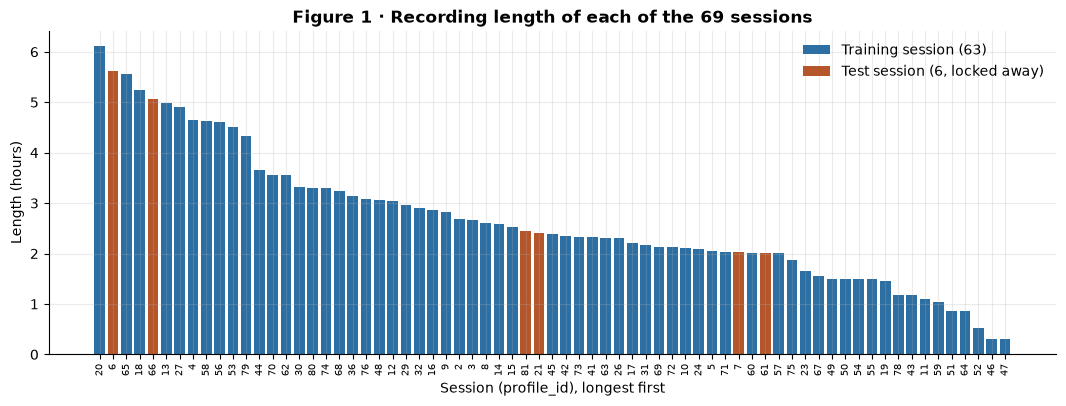

Training sessions: 0.302 to 6.107 h


In [7]:
order = sessions.sort_values("hours", ascending=False)
bar_colors = [COLORS["test"] if p in test_profiles else COLORS["train"] for p in order.index]

fig, ax = plt.subplots(figsize=(13, 4.2))
ax.bar(range(len(order)), order["hours"], color=bar_colors, width=0.8)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order.index, rotation=90, fontsize=7)
ax.set_xlabel("Session (profile_id), longest first")
ax.set_ylabel("Length (hours)")
ax.set_title("Figure 1 · Recording length of each of the 69 sessions")
ax.bar([0], [0], color=COLORS["train"], label=f"Training session ({len(train_profiles)})")
ax.bar([0], [0], color=COLORS["test"], label=f"Test session ({len(test_profiles)}, locked away)")
ax.legend(loc="upper right")
save_figure(fig, "eda_01_session_lengths.png")
plt.show()

print(f"Training sessions: {sessions.loc[train_profiles, 'hours'].min():.3f} to {sessions.loc[train_profiles, 'hours'].max():.3f} h")

## 6. Figure 2: one long session over time
Session **20** is the longest training session (6.1 h) and its winding goes from room temperature to well above 100 °C, so it shows a lot of behaviour. We plot the temperatures, speed, torque, current and voltages on one shared time axis (minutes), stacked so you can read across.

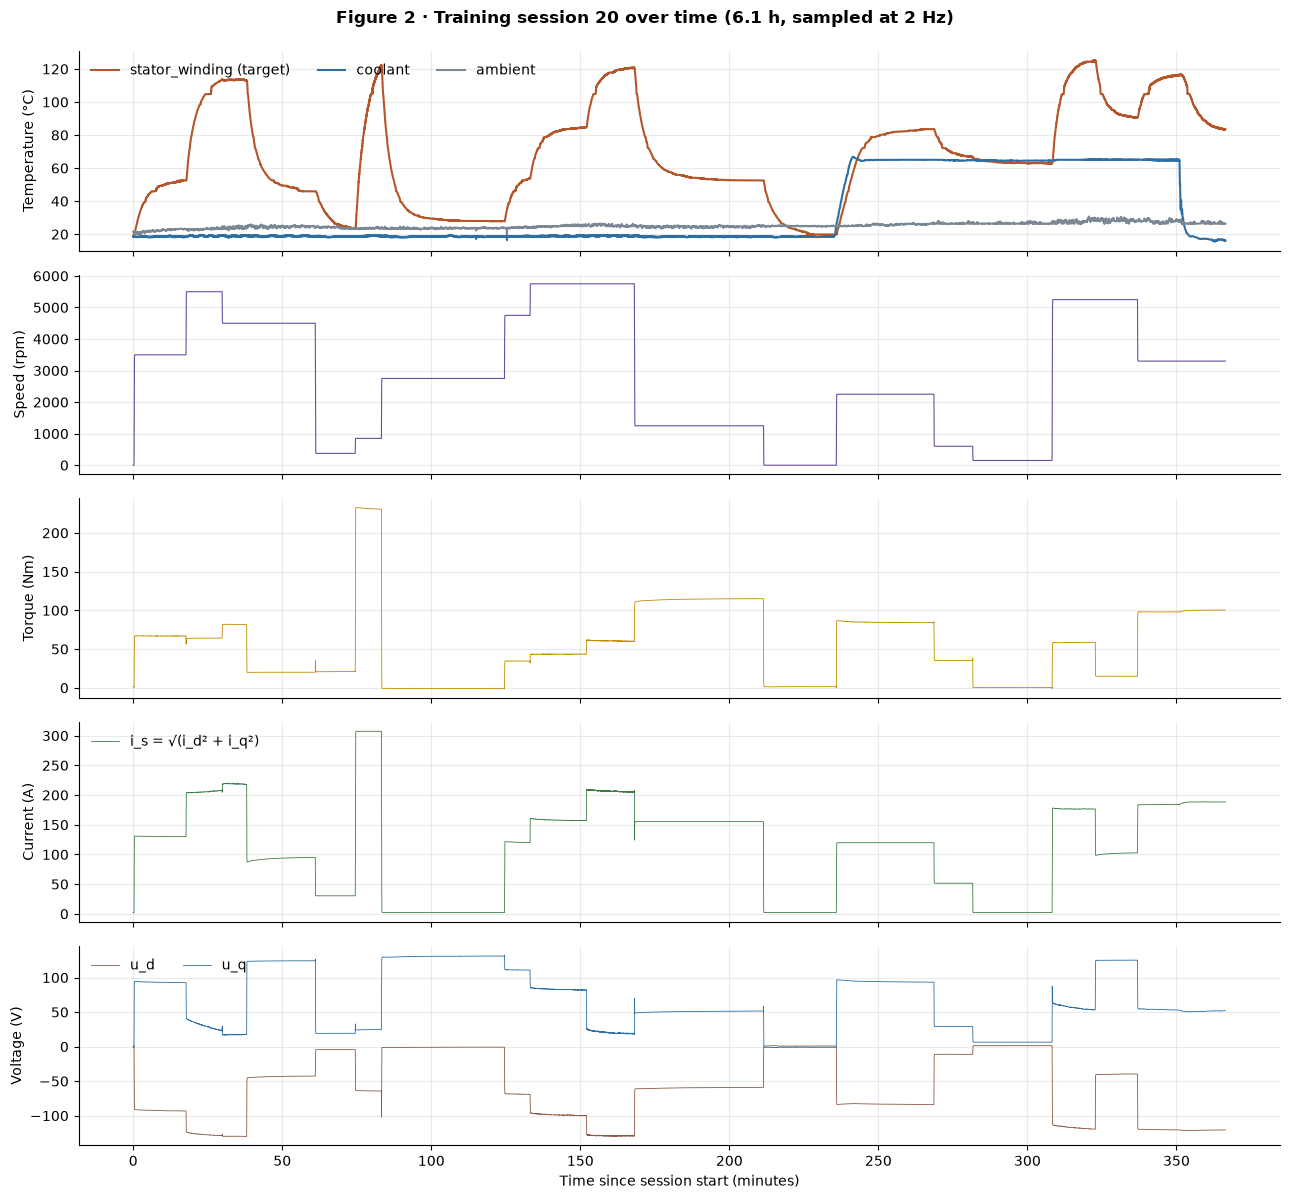

Session 20: winding 19.18 to 125.38 °C, coolant 15.59 to 66.91 °C


In [8]:
example_id = 20
ex = df_train[df_train[config.GROUP] == example_id].copy()
ex["minutes"] = np.arange(len(ex)) / config.SAMPLE_RATE_HZ / 60

fig, axes = plt.subplots(5, 1, figsize=(13, 12), sharex=True)
axes[0].plot(ex["minutes"], ex["stator_winding"], color=COLORS["stator_winding"], label="stator_winding (target)")
axes[0].plot(ex["minutes"], ex["coolant"], color=COLORS["coolant"], label="coolant")
axes[0].plot(ex["minutes"], ex["ambient"], color=COLORS["ambient"], label="ambient")
axes[0].set_ylabel("Temperature (°C)")
axes[0].legend(loc="upper left", ncol=3)

axes[1].plot(ex["minutes"], ex["motor_speed"], color=COLORS["speed"], lw=0.8)
axes[1].set_ylabel("Speed (rpm)")

axes[2].plot(ex["minutes"], ex["torque"], color=COLORS["torque"], lw=0.6)
axes[2].set_ylabel("Torque (Nm)")

axes[3].plot(ex["minutes"], ex["i_s"], color=COLORS["current"], lw=0.6, label="i_s = √(i_d² + i_q²)")
axes[3].set_ylabel("Current (A)")
axes[3].legend(loc="upper left")

axes[4].plot(ex["minutes"], ex["u_d"], color=COLORS["voltage"], lw=0.6, label="u_d")
axes[4].plot(ex["minutes"], ex["u_q"], color=COLORS["coolant"], lw=0.6, label="u_q")
axes[4].set_ylabel("Voltage (V)")
axes[4].set_xlabel("Time since session start (minutes)")
axes[4].legend(loc="upper left", ncol=2)

fig.suptitle(f"Figure 2 · Training session {example_id} over time (6.1 h, sampled at 2 Hz)", fontweight="bold", y=0.995)
fig.tight_layout()
save_figure(fig, "eda_02_session20_over_time.png")
plt.show()

print(f"Session {example_id}: winding {ex['stator_winding'].min():.2f} to {ex['stator_winding'].max():.2f} °C, "
      f"coolant {ex['coolant'].min():.2f} to {ex['coolant'].max():.2f} °C")

## 7. Figure 3: distribution of every column
A histogram shows how often each value occurs. We draw all 12 measured columns (training rows), with the target highlighted. The title of each panel gives its min and max.

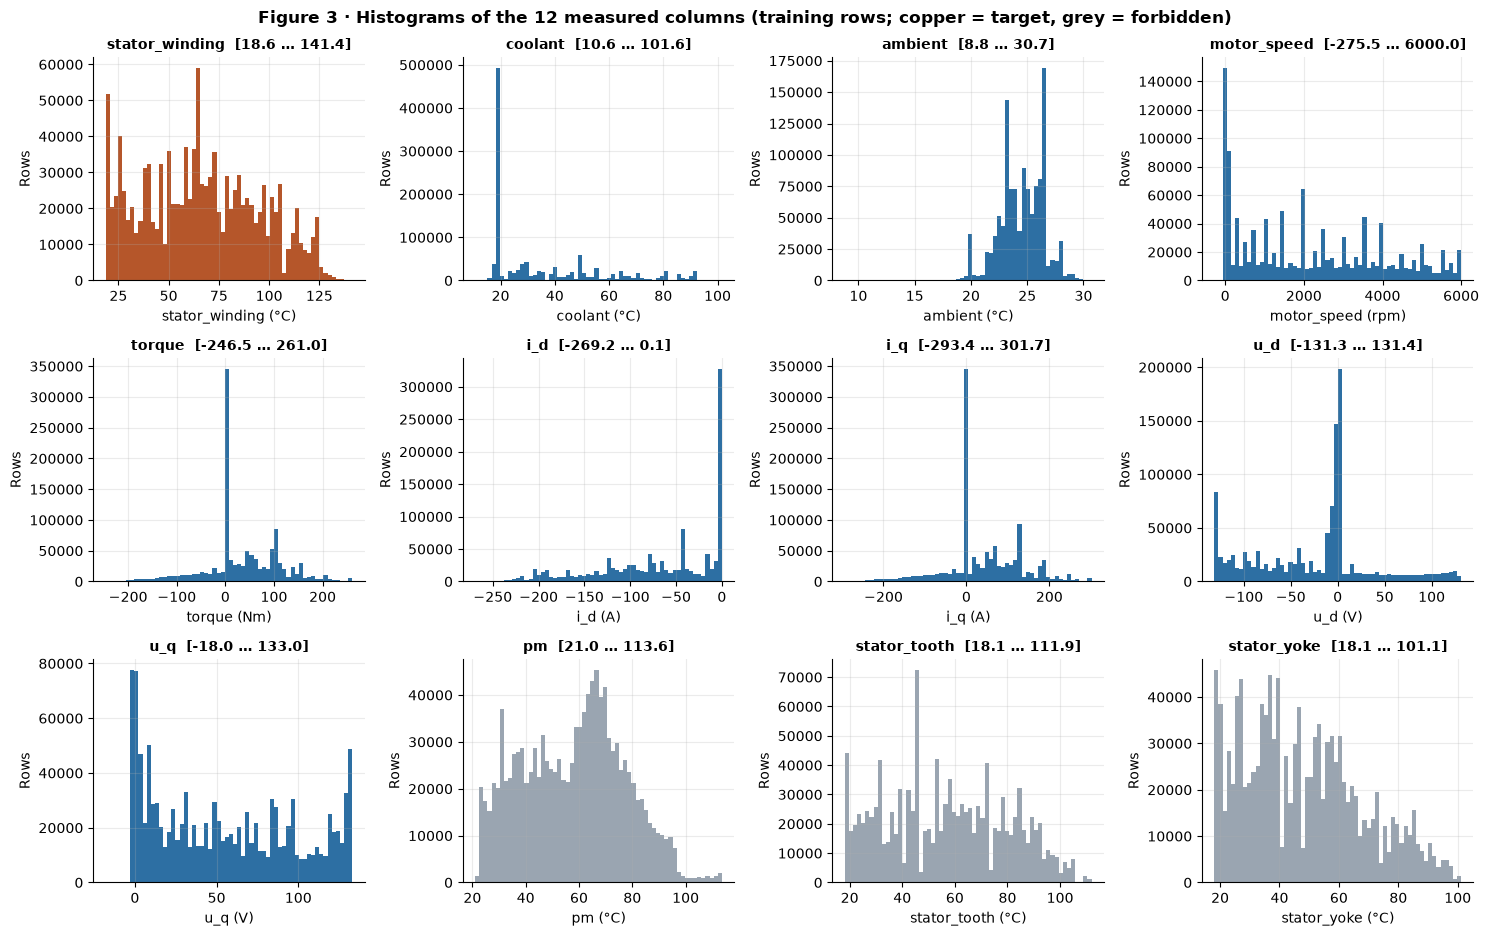

Target (training rows):
count    1189792.00
mean          66.17
std           28.98
min           18.59
10%           25.89
50%           64.63
90%          104.79
max          141.36


In [9]:
columns = ["stator_winding", "coolant", "ambient", "motor_speed", "torque", "i_d", "i_q", "u_d", "u_q", "pm", "stator_tooth", "stator_yoke"]
fig, axes = plt.subplots(3, 4, figsize=(15, 9.5))
for ax, col in zip(axes.ravel(), columns):
    color = COLORS["stator_winding"] if col == config.TARGET else ("#9aa5b1" if col in config.FORBIDDEN else COLORS["coolant"])
    ax.hist(df_train[col], bins=60, color=color)
    ax.set_title(f"{col}  [{df_train[col].min():.1f} … {df_train[col].max():.1f}]", fontsize=10)
    ax.set_xlabel(f"{col} ({UNITS[col]})")
    ax.set_ylabel("Rows")
fig.suptitle("Figure 3 · Histograms of the 12 measured columns (training rows; copper = target, grey = forbidden)", fontweight="bold")
fig.tight_layout()
save_figure(fig, "eda_03_histograms.png")
plt.show()

stats = df_train[config.TARGET].describe(percentiles=[0.1, 0.5, 0.9])
print("Target (training rows):")
print(stats.round(2).to_string())

## 8. Figure 4: correlation heatmap
**Pearson correlation** (r) measures how strongly two columns move together in a straight-line way: +1 = always up together, −1 = one up when the other is down, 0 = no straight-line link. It does **not** prove one causes the other.

We include the forbidden temperatures on purpose, to *show* why they would be cheating.

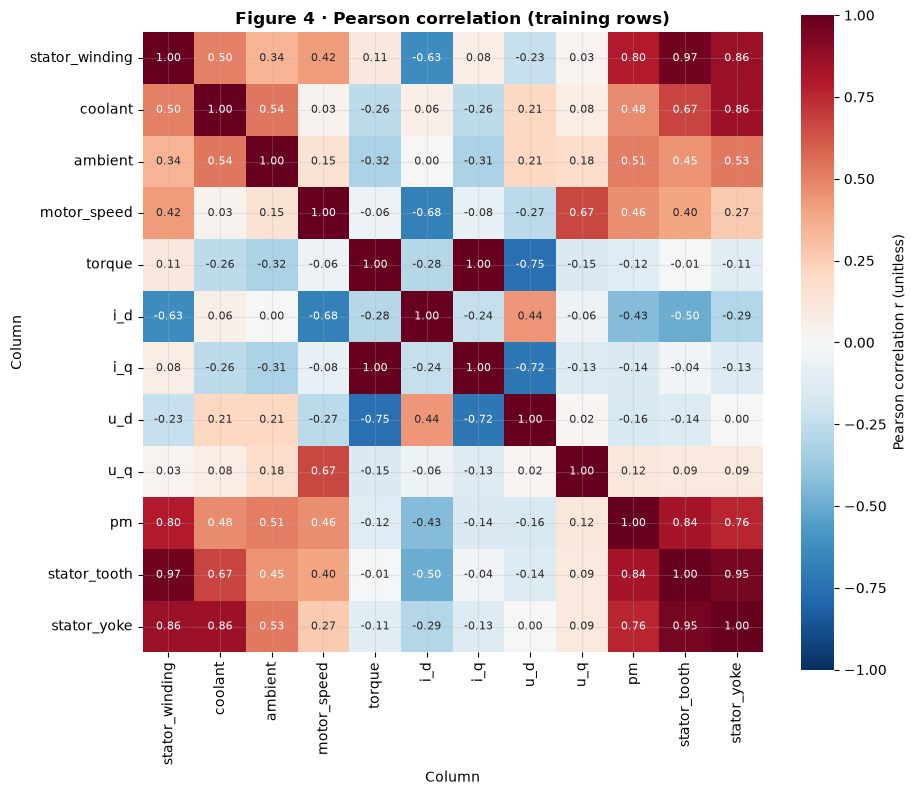

torque vs i_q: r = 0.9965


,r_with_stator_winding,role
stator_tooth,0.970,forbidden
stator_yoke,0.862,forbidden
pm,0.796,forbidden
i_d,-0.632,input
coolant,0.505,input
motor_speed,0.424,input
ambient,0.339,input
u_d,-0.229,input
torque,0.105,input
i_q,0.076,input


In [10]:
corr = df_train[columns].corr(method="pearson")

fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Pearson correlation r (unitless)"}, ax=ax, annot_kws={"size": 8})
ax.set_title("Figure 4 · Pearson correlation (training rows)")
ax.set_xlabel("Column")
ax.set_ylabel("Column")
save_figure(fig, "eda_04_correlation_heatmap.png")
plt.show()

corr.round(4).to_csv(config.RESULTS_DIR / "eda_correlation_matrix.csv")
print(f"torque vs i_q: r = {corr.loc['torque', 'i_q']:.4f}")

target_corr = corr[config.TARGET].drop(config.TARGET).sort_values(key=np.abs, ascending=False)
extra = pd.Series({
    "i_s (current magnitude)": np.corrcoef(df_train["i_s"], df_train[config.TARGET])[0, 1],
    "i_s_sq (current squared)": np.corrcoef(df_train["i_s_sq"], df_train[config.TARGET])[0, 1],
})
target_table = pd.concat([target_corr, extra]).rename("r_with_stator_winding").to_frame()
target_table["role"] = ["forbidden" if c in config.FORBIDDEN else ("derived (plot only)" if c.startswith("i_s") else "input") for c in target_table.index]
target_table.to_csv(config.RESULTS_DIR / "eda_target_correlations.csv")
target_table.round(3)

## 9. Figure 5: winding temperature vs current and vs coolant
With about 1.2 million points a normal scatter plot is a solid blob. A **hexbin** plot splits the area into hexagons and colours each by how many points fall inside (log scale), so we can see where the data really is.

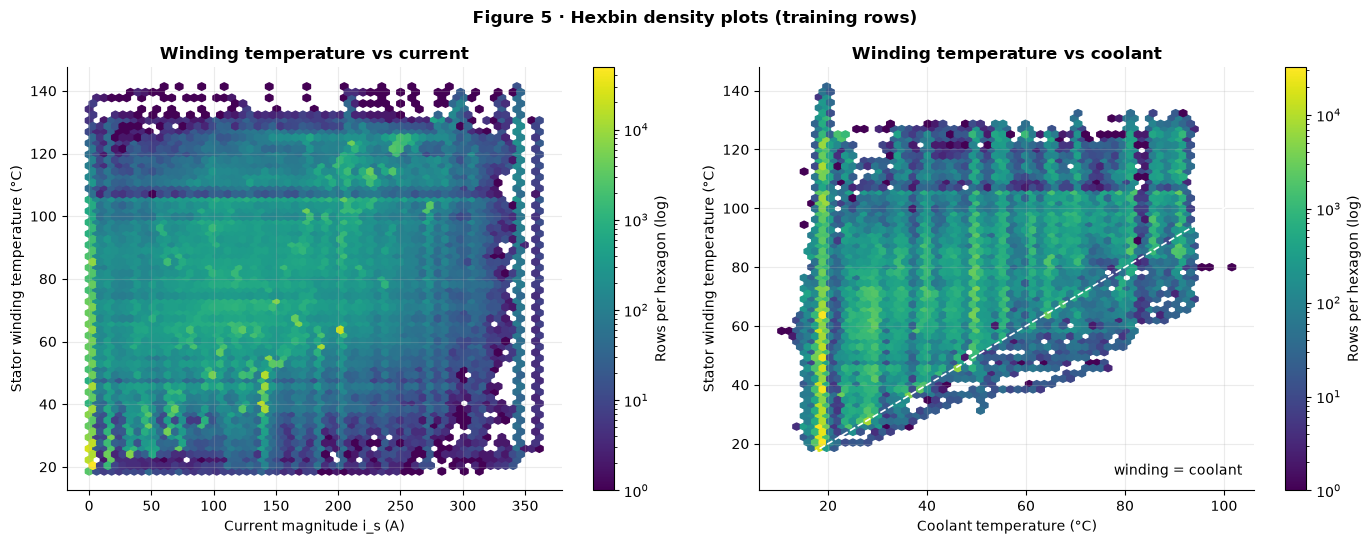

Winding minus coolant: min -29.66, median 26.47, max 121.39 °C
Rows where the winding is cooler than the coolant: 4.75 %


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
hb0 = axes[0].hexbin(df_train["i_s"], df_train[config.TARGET], gridsize=60, bins="log", mincnt=1, cmap="viridis")
axes[0].set_xlabel("Current magnitude i_s (A)")
axes[0].set_ylabel("Stator winding temperature (°C)")
axes[0].set_title("Winding temperature vs current")
fig.colorbar(hb0, ax=axes[0], label="Rows per hexagon (log)")

hb1 = axes[1].hexbin(df_train["coolant"], df_train[config.TARGET], gridsize=60, bins="log", mincnt=1, cmap="viridis")
lims = [df_train["coolant"].min(), df_train["coolant"].max()]
axes[1].plot(lims, lims, color="white", lw=1.2, ls="--", label="winding = coolant")
axes[1].set_xlabel("Coolant temperature (°C)")
axes[1].set_ylabel("Stator winding temperature (°C)")
axes[1].set_title("Winding temperature vs coolant")
axes[1].legend(loc="lower right")
fig.colorbar(hb1, ax=axes[1], label="Rows per hexagon (log)")
fig.suptitle("Figure 5 · Hexbin density plots (training rows)", fontweight="bold")
fig.tight_layout()
save_figure(fig, "eda_05_hexbin_current_and_coolant.png")
plt.show()

gap = df_train[config.TARGET] - df_train["coolant"]
below_coolant_pct = 100 * (gap < 0).mean()
print(f"Winding minus coolant: min {gap.min():.2f}, median {gap.median():.2f}, max {gap.max():.2f} °C")
print(f"Rows where the winding is cooler than the coolant: {below_coolant_pct:.2f} %")

## 10. Figure 6: the operating region
Each dot is one moment: where the motor was in the speed–torque plane, coloured by winding temperature. We plot a random 100,000 training rows (`random_state = 42`) so the plot stays readable. Sampling only affects this picture, not any analysis.

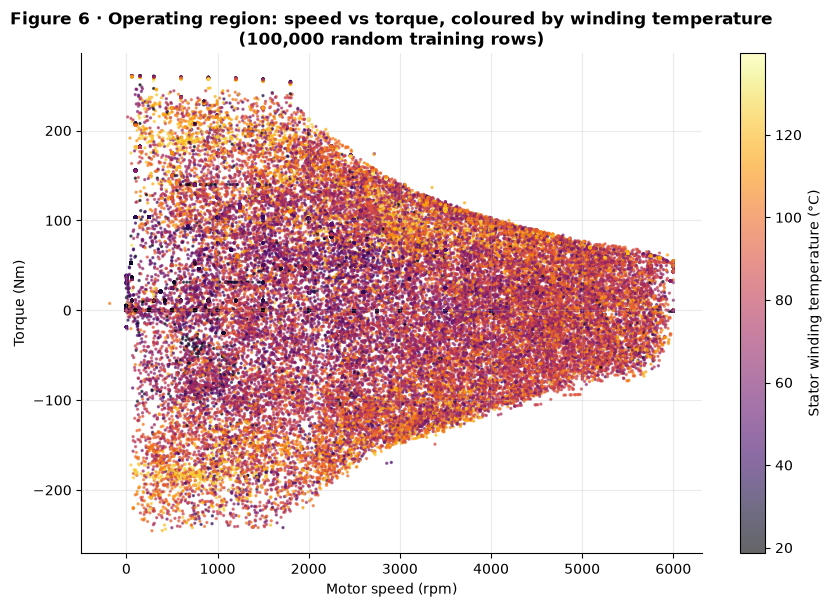

Median winding temperature by speed band (training rows):
motor_speed
< 1000 rpm       49.049999
1000–3000 rpm    62.459999
> 3000 rpm       82.919998


In [12]:
sample = df_train.sample(n=100_000, random_state=config.SEED)
fig, ax = plt.subplots(figsize=(10, 6.5))
sc = ax.scatter(sample["motor_speed"], sample["torque"], c=sample[config.TARGET], cmap="inferno", s=2, alpha=0.6)
fig.colorbar(sc, ax=ax, label="Stator winding temperature (°C)")
ax.set_xlabel("Motor speed (rpm)")
ax.set_ylabel("Torque (Nm)")
ax.set_title("Figure 6 · Operating region: speed vs torque, coloured by winding temperature\n(100,000 random training rows)")
save_figure(fig, "eda_06_operating_region.png")
plt.show()

speed_bins = pd.cut(df_train["motor_speed"], bins=[-300, 1000, 3000, 6100], labels=["< 1000 rpm", "1000–3000 rpm", "> 3000 rpm"])
print("Median winding temperature by speed band (training rows):")
print(df_train.groupby(speed_bins, observed=True)[config.TARGET].median().round(2).to_string())

## 11. Figure 7: winding temperature in each training session
One box per training session, sorted by its median. The box covers the middle 50 % of readings and the whiskers reach 1.5 × the box height. We hide individual outlier dots (`showfliers=False`), because with ~19,000 rows per session they would cover the plot.

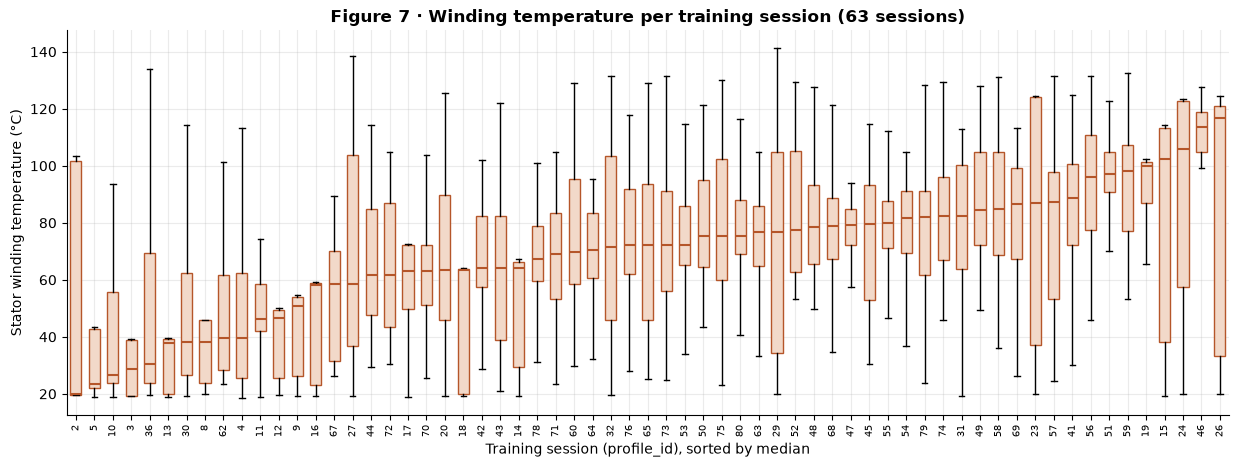

Session medians range from 19.88 to 116.74 °C
Session maxima range from 39.10 to 141.36 °C


In [13]:
per_session = df_train.groupby(config.GROUP)[config.TARGET]
order_ids = per_session.median().sort_values().index
data_for_boxes = [df_train.loc[df_train[config.GROUP] == p, config.TARGET].to_numpy() for p in order_ids]

fig, ax = plt.subplots(figsize=(15, 5))
ax.boxplot(data_for_boxes, showfliers=False, widths=0.6, patch_artist=True,
           boxprops={"facecolor": "#f2d9c9", "edgecolor": COLORS["stator_winding"]},
           medianprops={"color": COLORS["stator_winding"], "linewidth": 1.5})
ax.set_xticks(range(1, len(order_ids) + 1))
ax.set_xticklabels(order_ids, rotation=90, fontsize=7)
ax.set_xlabel("Training session (profile_id), sorted by median")
ax.set_ylabel("Stator winding temperature (°C)")
ax.set_title(f"Figure 7 · Winding temperature per training session ({len(order_ids)} sessions)")
save_figure(fig, "eda_07_boxplots_per_session.png")
plt.show()

session_summary = per_session.agg(["count", "min", "median", "max"]).rename(columns={"count": "n_rows"})
session_summary["hours"] = session_summary["n_rows"] / config.SAMPLE_RATE_HZ / 3600
session_summary.round(3).to_csv(config.RESULTS_DIR / "eda_session_summary.csv")
print(f"Session medians range from {session_summary['median'].min():.2f} to {session_summary['median'].max():.2f} °C")
print(f"Session maxima range from {session_summary['max'].min():.2f} to {session_summary['max'].max():.2f} °C")

## 12. Figure 8: the thermal lag (why the model needs memory)
If temperature reacted instantly to current, the two would rise and fall together. Because of **thermal inertia** (heat takes time to build up), the winding temperature should **lag behind** the heating signal `i_s²`.

We check this in two ways:
- **(a) Zoom in on one load step** in session 20: we find the biggest jump of `i_s²` within 10 seconds, and plot 10 minutes before to 40 minutes after it.
- **(b) Lagged correlation:** for each training session at least 90 min long, compute the correlation between `i_s²` at time *t* and winding temperature at time *t + lag*, for lags 0 to 60 minutes. Where the curve peaks is the lag at which past current "explains" today's temperature best.

In [14]:
# (a) find the biggest jump of i_s² within 10 s (20 rows) in session 20
ex_sq = ex["i_d"].astype("float64") ** 2 + ex["i_q"].astype("float64") ** 2
jump = ex_sq.diff(20).to_numpy()
step_row = int(np.nanargmax(jump))
start = max(step_row - 10 * 120, 0)
stop = min(step_row + 40 * 120, len(ex))
window_minutes = (np.arange(start, stop) - step_row) / config.SAMPLE_RATE_HZ / 60
print(f"Biggest current step in session {example_id} at minute {step_row / 120:.1f}: "
      f"i_s from {np.sqrt(ex_sq.iloc[step_row - 20]):.1f} A to {np.sqrt(ex_sq.iloc[step_row]):.1f} A")

Biggest current step in session 20 at minute 74.7: i_s from 34.1 A to 305.9 A


In [15]:
# (b) lagged correlation, per training session
lags_min = np.arange(0, 60.5, 0.5)

def lag_curve(session):
    x = (session["i_d"].astype("float64") ** 2 + session["i_q"].astype("float64") ** 2).to_numpy()
    y = session[config.TARGET].astype("float64").to_numpy()
    curve = []
    for lag in lags_min:
        k = int(lag * 60 * config.SAMPLE_RATE_HZ)
        x_part = x[: len(x) - k] if k > 0 else x
        curve.append(np.corrcoef(x_part, y[k:])[0, 1])
    return np.array(curve)

curves = {}
for pid, session in df_train.groupby(config.GROUP):
    if len(session) >= 90 * 60 * config.SAMPLE_RATE_HZ:
        curves[pid] = lag_curve(session)

lag_table = pd.DataFrame({
    "profile_id": list(curves.keys()),
    "corr_at_lag_0": [c[0] for c in curves.values()],
    "best_lag_min": [lags_min[np.nanargmax(c)] for c in curves.values()],
    "best_corr": [np.nanmax(c) for c in curves.values()],
})
lag_table.round(4).to_csv(config.RESULTS_DIR / "eda_thermal_lag_per_session.csv", index=False)
median_curve = np.nanmedian(np.vstack(list(curves.values())), axis=0)

print("Sessions analysed (>= 90 min):", len(lag_table))
print(f"Median best lag: {lag_table['best_lag_min'].median():.1f} min "
      f"(25th-75th percentile {lag_table['best_lag_min'].quantile(0.25):.1f} to {lag_table['best_lag_min'].quantile(0.75):.1f} min)")
print(f"Median correlation at lag 0: {lag_table['corr_at_lag_0'].median():.3f} -> at best lag: {lag_table['best_corr'].median():.3f}")
print(f"Sessions whose best lag is under 5 min: {(lag_table['best_lag_min'] < 5).sum()} of {len(lag_table)}")

Sessions analysed (>= 90 min): 53
Median best lag: 2.5 min (25th-75th percentile 1.0 to 3.0 min)
Median correlation at lag 0: 0.645 -> at best lag: 0.746
Sessions whose best lag is under 5 min: 47 of 53


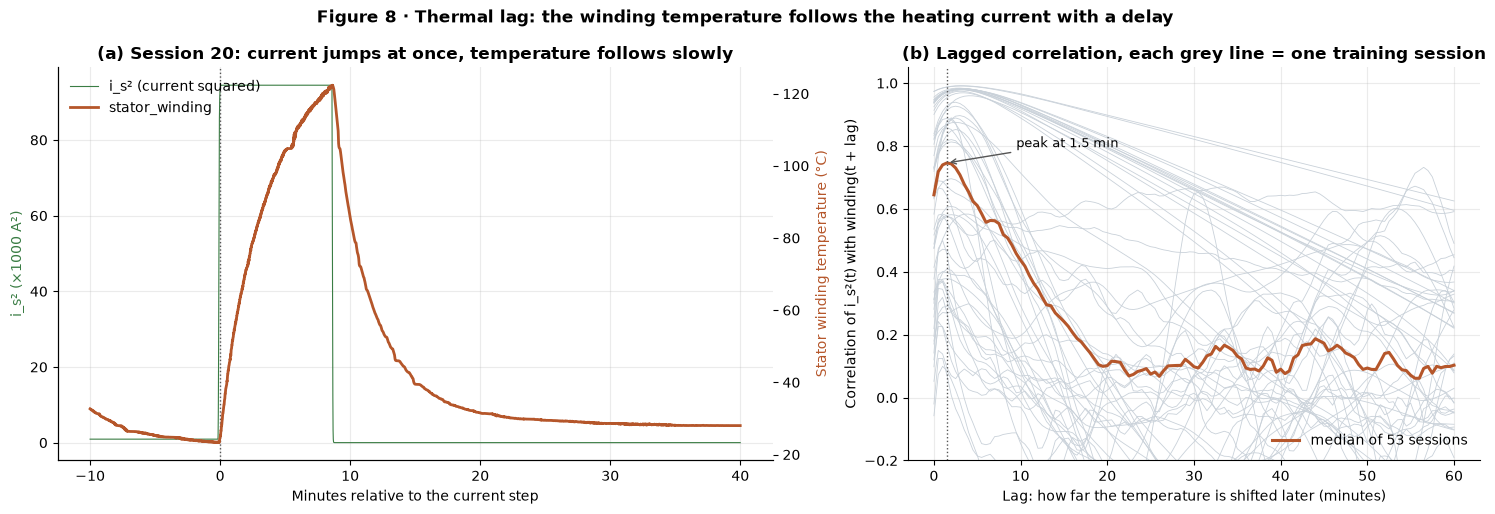

Median curve: r = 0.645 at lag 0, peak r = 0.746 at 1.5 min


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})

ax = axes[0]
ax.plot(window_minutes, ex_sq.to_numpy()[start:stop] / 1000, color=COLORS["current"], lw=0.8, label="i_s² (current squared)")
ax.set_xlabel("Minutes relative to the current step")
ax.set_ylabel("i_s² (×1000 A²)", color=COLORS["current"])
ax.axvline(0, color="#555555", ls=":", lw=1)
ax2 = ax.twinx()
ax2.plot(window_minutes, ex[config.TARGET].to_numpy()[start:stop], color=COLORS["stator_winding"], lw=2, label="stator_winding")
ax2.set_ylabel("Stator winding temperature (°C)", color=COLORS["stator_winding"])
ax2.grid(False)
lines = ax.get_lines()[:1] + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], loc="upper left")
ax.set_title(f"(a) Session {example_id}: current jumps at once, temperature follows slowly")

ax = axes[1]
for c in curves.values():
    ax.plot(lags_min, c, color="#c9d1d9", lw=0.6)
ax.plot(lags_min, median_curve, color=COLORS["stator_winding"], lw=2.2, label=f"median of {len(curves)} sessions")
best = lags_min[np.nanargmax(median_curve)]
ax.axvline(best, color="#555555", ls=":", lw=1)
ax.annotate(f"peak at {best:.1f} min", xy=(best, np.nanmax(median_curve)), xytext=(best + 8, np.nanmax(median_curve) + 0.05),
            arrowprops={"arrowstyle": "->", "color": "#555555"}, fontsize=9)
ax.set_xlabel("Lag: how far the temperature is shifted later (minutes)")
ax.set_ylabel("Correlation of i_s²(t) with winding(t + lag)")
ax.set_ylim(-0.2, 1.05)
ax.set_title("(b) Lagged correlation, each grey line = one training session")
ax.legend(loc="lower right")

fig.suptitle("Figure 8 · Thermal lag: the winding temperature follows the heating current with a delay", fontweight="bold")
fig.tight_layout()
save_figure(fig, "eda_08_thermal_lag.png")
plt.show()
print(f"Median curve: r = {median_curve[0]:.3f} at lag 0, peak r = {np.nanmax(median_curve):.3f} at {best:.1f} min")

## 13. Follow-ups from Phase 0 (data quality)
The Phase 0 handover asked for two things. Both are audits of the raw signals on the full file, as in notebook 01:
- Where is the **8.78 °C ambient** reading (about 8 standard deviations below the mean)?
- Where is the **1.39 °C jump** in winding temperature between two rows 0.5 s apart?

In [17]:
low_ambient = df[df["ambient"] < 15]
print("Rows with ambient < 15 °C, per session:", low_ambient.groupby(config.GROUP).size().to_dict())
print(f"Lowest ambient: {df['ambient'].min():.2f} °C in session {int(df.loc[df['ambient'].idxmin(), config.GROUP])}")

row_in_session = df.groupby(config.GROUP).cumcount()
step = df.groupby(config.GROUP)[config.TARGET].diff().abs()
jump_idx = step.idxmax()
jump_session = int(df.loc[jump_idx, config.GROUP])
print(f"Biggest one-step winding change: {step.max():.3f} °C in session {jump_session}, "
      f"at minute {row_in_session[jump_idx] / 120:.1f} of that session")
print("Are both in training sessions?", int(df.loc[df['ambient'].idxmin(), config.GROUP]) in train_profiles, jump_session in train_profiles)

Rows with ambient < 15 °C, per session: {44: 4, 68: 1}
Lowest ambient: 8.78 °C in session 44
Biggest one-step winding change: 1.394 °C in session 65, at minute 82.1 of that session
Are both in training sessions? True True


## 14. Save every EDA number
Team rule: every number we quote must come from a results file.

In [18]:
summary = {
    "split_file": "outputs/results/split_profiles.json",
    "test_profiles": test_profiles,
    "n_train_sessions": len(train_profiles),
    "n_train_rows": int(len(df_train)),
    "test_share_of_rows": round(float(test_share), 4),
    "draws_needed": attempt,
    "target_train_stats": {k: round(float(v), 3) for k, v in df_train[config.TARGET].describe(percentiles=[0.1, 0.5, 0.9]).items()},
    "corr_with_target": {k: round(float(v), 3) for k, v in target_table["r_with_stator_winding"].items()},
    "winding_minus_coolant": {"min": round(float(gap.min()), 3), "median": round(float(gap.median()), 3),
                              "max": round(float(gap.max()), 3), "pct_rows_below_zero": round(float(below_coolant_pct), 3)},
    "median_winding_by_speed_band": {str(k): round(float(v), 3) for k, v in df_train.groupby(speed_bins, observed=True)[config.TARGET].median().items()},
    "session_median_range": [round(float(session_summary["median"].min()), 3), round(float(session_summary["median"].max()), 3)],
    "session_max_range": [round(float(session_summary["max"].min()), 3), round(float(session_summary["max"].max()), 3)],
    "thermal_lag": {
        "sessions_analysed": int(len(lag_table)),
        "median_best_lag_min": float(lag_table["best_lag_min"].median()),
        "p25_best_lag_min": float(lag_table["best_lag_min"].quantile(0.25)),
        "p75_best_lag_min": float(lag_table["best_lag_min"].quantile(0.75)),
        "median_corr_at_lag0": round(float(lag_table["corr_at_lag_0"].median()), 3),
        "median_best_corr": round(float(lag_table["best_corr"].median()), 3),
        "median_curve_peak_lag_min": float(best),
        "median_curve_r_lag0": round(float(median_curve[0]), 3),
        "median_curve_r_peak": round(float(np.nanmax(median_curve)), 3),
        "sessions_best_lag_under_5_min": int((lag_table["best_lag_min"] < 5).sum()),
    },
    "example_session": example_id,
    "example_step_minute": round(step_row / 120, 1),
    "low_ambient_rows_per_session": {str(k): int(v) for k, v in low_ambient.groupby(config.GROUP).size().items()},
    "biggest_step": {"deg_c": round(float(step.max()), 3), "session": jump_session, "minute": round(float(row_in_session[jump_idx] / 120), 1)},
    "figures": sorted(p.name for p in config.FIGURES_DIR.glob("eda_*.png")),
}
with open(config.RESULTS_DIR / "eda_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print("Saved:", config.RESULTS_DIR / "eda_summary.json")

Saved: D:\TIET Stuff\Semester 3\AI for Engineers (UCS321)\Project stuff\MST_Motor_Temperature\Ai-for-engineers-MST-project\outputs\results\eda_summary.json


## 15. Export compact data for the interactive showcase page
`docs/showcase/index.html` is an interactive page for the presentation. It can't load 1.2 million rows, so we export **1-minute averages** of the **training sessions only** (the test sessions stay locked away even here), plus the numbers behind figures 4, 6 and 8. The file is written as a small JavaScript file so the page also works when opened straight from disk.

In [19]:
showcase_dir = PROJECT_DIR / "docs" / "showcase"
showcase_dir.mkdir(parents=True, exist_ok=True)

traces = {}
for pid, session in df_train.groupby(config.GROUP):
    minute = np.arange(len(session)) // (60 * config.SAMPLE_RATE_HZ)
    m = session.assign(minute=minute).groupby("minute")[["stator_winding", "coolant", "ambient", "i_s", "motor_speed", "torque"]].mean()
    traces[str(pid)] = {
        "w": m["stator_winding"].round(1).tolist(),
        "c": m["coolant"].round(1).tolist(),
        "a": m["ambient"].round(1).tolist(),
        "i": m["i_s"].round(1).tolist(),
        "n": m["motor_speed"].round(0).astype(int).tolist(),
        "t": m["torque"].round(1).tolist(),
    }

# mean winding temperature on a speed x torque grid (figure 6 as numbers)
speed_edges = np.linspace(-300, 6100, 33)
torque_edges = np.linspace(-250, 265, 31)
grid = df_train.assign(
    sb=pd.cut(df_train["motor_speed"], speed_edges, labels=False),
    tb=pd.cut(df_train["torque"], torque_edges, labels=False),
).groupby(["sb", "tb"])[config.TARGET].agg(["mean", "size"]).reset_index()

showcase = {
    "sessions": [{"id": int(p), "hours": round(float(sessions.loc[p, "hours"]), 3), "test": p in test_profiles} for p in sessions.index],
    "traces": traces,
    "corr": {"cols": columns, "values": corr.round(3).values.tolist()},
    "lag": {"lags": lags_min.tolist(), "median": np.round(median_curve, 3).tolist(),
            "best": lag_table.round(3).to_dict(orient="list")},
    "opgrid": {"speed_edges": speed_edges.round(1).tolist(), "torque_edges": torque_edges.round(1).tolist(),
               "cells": [[int(r.sb), int(r.tb), round(float(r["mean"]), 1), int(r["size"])] for _, r in grid.iterrows()]},
    "summary": summary,
}
js_path = showcase_dir / "eda_data.js"
with open(js_path, "w", encoding="utf-8") as f:
    f.write("window.EDA_DATA = ")
    json.dump(showcase, f, separators=(",", ":"))
    f.write(";\n")
print(f"Saved {js_path.name}: {js_path.stat().st_size / 1e6:.2f} MB, {len(traces)} training sessions")

Saved eda_data.js: 0.74 MB, 63 training sessions


## 16. What we found (all numbers are from the outputs above and `outputs/results/eda_summary.json`)

**Per figure**
1. **Session lengths (Fig 1):**
   - The 69 sessions last from 0.302 to 6.107 h.
   - The frozen test set has sessions 6 and 66 (long), 21 and 81 (medium), and 7 and 61 (short group, about 2 h each). That's 10.60 % of rows, found on the first draw.
   - Training: 63 sessions, 1,189,792 rows.
2. **Session 20 over time (Fig 2):** this session holds speed and torque steady for minutes at a time (a step-by-step driving cycle). After every step the winding temperature moves along a smooth curve, not a jump. When the coolant temperature is raised partway through, the "floor" of the winding temperature rises with it. Winding range: 19.18–125.38 °C.
3. **Distributions (Fig 3):**
   - The target (training rows) runs from 18.59 to 141.36 °C, with median 64.63 °C, 10th percentile 25.89 °C and 90th percentile 104.79 °C.
   - The coolant spends most of its time near one low setting (the tall spike).
   - Speed sits on a few fixed levels, and torque and `i_q` have a spike at 0 (motor idling).
   - `i_d` is never clearly positive.
4. **Correlation (Fig 4):**
   - The forbidden columns correlate very strongly with the target: `stator_tooth` 0.970, `stator_yoke` 0.862, `pm` 0.796. That's proof they would leak.
   - The best allowed inputs are much weaker: `i_d` −0.632, `coolant` 0.505, `motor_speed` 0.424.
   - **`torque` and `i_q` correlate at r = 0.9965**, so torque carries almost the same information as `i_q`.
5. **Hexbins (Fig 5):**
   - At almost every current value, the winding temperature spans nearly its whole range. Even at about 0 A it can be cold or hot. The present current alone cannot tell the temperature.
   - The winding is usually hotter than the coolant (median gap 26.47 °C), but in 4.75 % of rows it is *cooler* (down to −29.66 °C). This happens when the coolant is heated faster than the winding can follow.
6. **Operating region (Fig 6):**
   - The data covers the motor's whole torque–speed envelope: high torque at low speed, and a falling torque limit at high speed.
   - Hot and cool dots are mixed everywhere, so the operating point alone doesn't fix the temperature.
   - Median winding temperature by speed band: 49.05 °C below 1000 rpm, 62.46 °C at 1000–3000 rpm, 82.92 °C above 3000 rpm.
7. **Per-session boxplots (Fig 7):** session medians range from 19.88 to 116.74 °C, and session maxima from 39.10 to 141.36 °C. Sessions are very different from each other.
8. **Thermal lag (Fig 8):**
   - (a) When the current steps from 34.1 A to 305.9 A (session 20, minute 74.7), the temperature does not jump. It climbs for the whole time the current stays on, and after the current drops it takes many minutes to cool down.
   - (b) Across the 53 training sessions of at least 90 min, the correlation between `i_s²(t)` and winding(t + lag) is highest at a **median lag of 2.5 min** (25th–75th percentile 1.0–3.0 min). The median correlation rises from **0.645 at lag 0 to 0.746 at the best lag**, and 47 of the 53 sessions peak below 5 min.

**Data-quality follow-ups from Phase 0**
- The 8.78 °C ambient reading belongs to **session 44**: 4 rows below 15 °C there, plus 1 row in session 68. These are brief dips; we keep them (no cleaning needed).
- The 1.394 °C one-step jump is in **session 65**, at minute 82.1. Both sessions are training sessions.

### Top-5 EDA insights
1. **The forbidden temperatures would leak.** They reach r = 0.970 / 0.862 / 0.796 with the target, while the best allowed input reaches |r| = 0.632. Excluding them is essential, and Phase 6 will show it with numbers.
2. **No single allowed signal explains the winding temperature.** The best |r| is 0.632, and at the same current the temperature can be anything from cold to hot. We need several inputs together and non-linear models.
3. **The winding has thermal memory.** Temperature follows the heating signal `i_s²` with a delay of minutes (median best lag 2.5 min; r 0.645 → 0.746), and heats and cools along smooth curves. This is the evidence for the **EWMA "memory" features** in Phase 3 (spans of 1, 5, 15 and 45 min).
4. **Coolant sets the floor, with its own lag.** The winding is usually 26.47 °C (median) above the coolant, but in 4.75 % of rows it is below it, right after the coolant is heated. Coolant history matters too, not just its current value.
5. **Sessions differ a lot.** Lengths run 0.302–6.107 h and medians 19.88–116.74 °C. This is why we split by whole sessions, evaluate per session, and report the unweighted mean of per-session errors. Also, torque ≈ `i_q` (r = 0.9965), which supports testing the model without torque.